Decomposition of LWA Carrying Capacity into different contributions

This notebook follows the analysis by Barpanda et al. 2024 https://doi.org/10.1175/JCLI-D-24-0232.1 

We want to compute the Total LWA Carrying Capacity:
\begin{equation}
F_c(x) = \frac{C^2(x)}{4\alpha} = \frac{\left( u_0 + c_g^x - 2\alpha \mathcal{A}_0 \right)^2}{4\alpha}
\end{equation}
In order to do so we need to compute:

- $u_0 + c_g^x$: this is computed as a regression coefficient between vertically-averaged linear zonal LWA flux $(𝐹_1 + 𝐹_3)$ and the wave-activity $(A cos\phi)$
- $\alpha$: this is the correlation coefficient between reference zonal winds and LWA. It can therefore be computed as −($u^′_e$$A^′_𝑇$ )/($A^′$$A^′_𝑇$ )
- ${A}_0$: this is the stationary waves induced local wave activity and can be computed by computing the local wave activity of the time-averaged qgpv field.

The Total LWA Carrying Capacity can therefore be decomposed in the following terms:

- 


In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil
import numpy as np
from tqdm import tqdm
import matplotlib.gridspec as gridspec  # To control widths
from scipy.integrate import trapezoid
import falwa.utilities as utilities
from falwa.oopinterface import QGFieldNH18
from math import pi
import cftime

### Necessary functions

In [2]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [3]:
from scipy.signal import butter, filtfilt

import xarray as xr
import numpy as np

import xarray as xr

import xarray as xr

def rolling_periodic(
    da: xr.DataArray,
    dim: str,
    window: int,
    center: bool = True
) -> xr.DataArray:

    n = window // 2 if center else window - 1

    # Extend array by wrapping values from both ends along chosen dimension
    da_extended = xr.concat([da.isel({dim: slice(-n, None)}),
                             da,
                             da.isel({dim: slice(0, n)})],
                            dim=dim)

    # Apply rolling mean
    rolled = da_extended.rolling({dim: window}, center=center).mean()

    # Trim back to original length
    result = rolled.isel({dim: slice(n, -n)})
    result[dim] = da[dim]  # restore original coords

    return result

def lowpass_fourier(da, period_days=4 , dt=1, time_dim='time'):
    
    n_time = da.sizes[time_dim]

    # FFT frequencies (cycles per day)
    freqs = np.fft.fftfreq(n_time, d=dt)
    cutoff = 1 / period_days  # max frequency to keep

    # FFT along time axis
    fft_vals = np.fft.fft(da, axis=0)

    # Low-pass mask
    mask = np.abs(freqs) <= cutoff
    fft_vals_filtered = fft_vals * mask[:, np.newaxis, np.newaxis]

    # Inverse FFT
    filtered_data = np.fft.ifft(fft_vals_filtered, axis=0).real

    return xr.DataArray(filtered_data, dims=da.dims, coords=da.coords, name=da.name)

def longitude_running_avg(da, lon_window_deg=15, lon_dim='lon'):
    # Compute number of points corresponding to lon_window_deg
    lon_vals = da[lon_dim].values
    if len(lon_vals) > 1:
        lon_res = np.mean(np.diff(lon_vals))
        window_points = max(1, int(np.round(lon_window_deg / lon_res)))
    else:
        window_points = 1

    print('longitudinal filter window: '+ str(window_points))

    # Apply rolling mean along longitude
    da_smoothed = rolling_periodic(da, lon_dim , window = window_points, center=True)
    return da_smoothed

def deseasonalize_daily(da):
    daily_clim = da.groupby("time.dayofyear").mean("time")
    anomalies = da.groupby("time.dayofyear") - daily_clim    
    return anomalies

def deseasonalize_roll(da):
    running_mean = rolling_periodic(da=da,dim='time',window=30,center=True)
    anomalies = da - running_mean  
    return anomalies

In [4]:
def compute_covariance_xr(A,B):
    
    #A = A.where(np.isfinite(A), 0)
    #B = B.where(np.isfinite(B), 0)
    #A = A.where(np.isnan(A), 0)
    #B = B.where(np.isnan(B), 0)
    
    # Compute means lazily (Dask-aware)
    A_mean = A.mean(dim='time')
    B_mean = B.mean(dim='time')
    
    # Compute anomalies lazily
    A_anom = A - A_mean
    B_anom = B - B_mean
    
    # Covariance calculation
    cov = (A_anom * B_anom).mean(dim='time')
    return cov

def covariance_bootstrap(A,B,n_iterations,n_sample):
    length = len(A)
    cov_set = []
    for n in tqdm(range(n_iterations)):
        idxs = np.random.choice(np.arange(0,length,1),size=n_sample,replace=False)
        cov_set.append(compute_covariance_xr(A[idxs],B[idxs]))
    cov_set_da = xr.concat(cov_set,dim = 'realization')
    return cov_set_da.std('realization')*(np.sqrt(n_sample)/np.sqrt(len(A)))        

### Importing data

In [5]:
#here we focus on the asymmetric baseline simulation
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/falwa_output/

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/falwa_output


In [8]:
#apply filters (if not done previously)
apply = False
if apply:
    months_range = range(13, 613) #select months range
    files_falwa = [f"falwa_output_1.5x1.5_{str(i).zfill(4)}.nc" for i in months_range]
    files_uvt = [f"atm_daily_uvt__{str(i).zfill(4)}.nc" for i in months_range]
    ds_fluxs = xr.open_mfdataset(files_falwa, combine="by_coords",parallel=True)
    ds_fluxs = flip_and_append(ds_fluxs)
    lwa = ds_fluxs['dw_lwa']
    ucomp = ds_fluxs['u_baro'] - ds_fluxs['dw_uref']
    F1 = ds_fluxs['adv_flux_f1']
    F2 = ds_fluxs['adv_flux_f2']
    F3 = ds_fluxs['adv_flux_f3']
    lwa = longitude_running_avg(lowpass_fourier(lwa))
    ucomp = longitude_running_avg(lowpass_fourier(ucomp))
    F1 = longitude_running_avg(lowpass_fourier(F1))
    F2 = longitude_running_avg(lowpass_fourier(F2))
    F3 = longitude_running_avg(lowpass_fourier(F3))
    ds_filtered = lwa.to_dataset()
    ds_filtered['F1'] = F1
    ds_filtered['F2'] = F2
    ds_filtered['F3'] = F3
    ds_filtered['dw_uref'] = ds_fluxs['dw_uref']
    ds_filtered['ucomp'] = ucomp
    ds_filtered.to_netcdf('../tot/filtered_decomposition_data_flipped_2-51.nc')
    ds_filtered.close()

longitudinal filter window: 10
longitudinal filter window: 10


/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/numpy/fft/_pocketfft.py:94: RuntimeWarning: invalid value encountered in fft
  return ufunc(a, fct, axes=[(axis,), (), (axis,)], out=out)


longitudinal filter window: 10
longitudinal filter window: 10
longitudinal filter window: 10


/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


In [9]:
#import dataset with decomposition data (output of previous cell)
ds = xr.open_dataset('../tot/filtered_decomposition_data_flipped_2-51.nc')
lwa = ds['dw_lwa']
ucomp = ds['ucomp']
zonal_flux = ds['F1'] + ds['F3']
lon = ds['lon']
lat = ds['lat']
cosphi = np.cos(np.deg2rad(lat)).broadcast_like(ucomp)

In [10]:
print(lwa.shape)

(36000, 61, 240)


## Computing $\alpha$

$\alpha$ measures the anticorrelation between u and A

In formula it is given by:

𝑢𝑒 ≈ −𝛼A, 𝛼 > 0.

Or:

𝛼 = −($u^′_e$$A^′_𝑇$ )/($A^′$$A^′_𝑇$ ), where A′, 𝑢′ 𝑒 are row matrices containing the time-filtered transient LWA and zonal wind, respectively.

In [11]:
print('computing covariances')
cov = compute_covariance_xr(lwa/cosphi,ucomp) #covariance
var = compute_covariance_xr(lwa/cosphi,lwa/cosphi) #lwa variance
alpha = (-cov/var).persist()

neg_cov = - cov.copy()
var_lwa = var.copy()
var_ucomp = compute_covariance_xr(ucomp,ucomp)

#compute error
#cov_std = covariance_bootstrap(lwa/cosphi,ucomp,50,1000) #covariance error
#var_std = covariance_bootstrap(lwa/cosphi,lwa/cosphi,50,1000) #lwa variance error
#alpha_std = np.abs(alpha)*(np.sqrt((cov_std/cov)**2)+(var_std/var)**2) #propagating the error to alpha

computing covariances


100%|███████████████████████████████████████████████████████████████████████| 50/50 [00:20<00:00,  2.49it/s]


In [12]:
ue_A_rvalue = neg_cov/np.sqrt(var_lwa*var_ucomp)
r_mask = np.where(ue_A_rvalue<0.4,1,0)

In [13]:
print('computing zonal average')
da_avg = alpha.mean(axis=-1).values
alpha_zon_mean = np.broadcast_to(da_avg[:, np.newaxis], alpha.shape)

computing zonal average


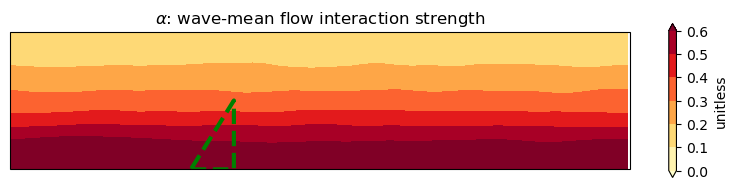

In [14]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon, lat, alpha,
    levels=np.arange(0, 0.7, 0.1),
    cmap='YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

ax.set_aspect(1.6)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='unitless',shrink=0.5)
plt.title(r'$\alpha$: wave-mean flow interaction strength')

plt.show()


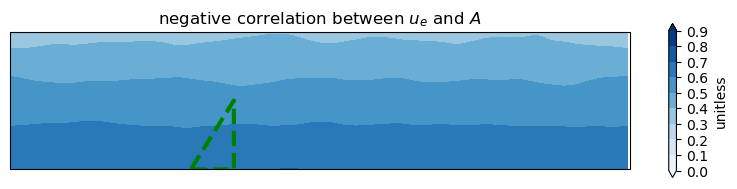

In [15]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon, lat, neg_cov/np.sqrt(var_lwa*var_ucomp),
    levels=np.arange(0, 1, 0.1),
    cmap='Blues',
    extend='both',
    transform=ccrs.PlateCarree()
)

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

ax.set_aspect(1.6)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='unitless',shrink=0.5)
plt.title(r'negative correlation between $u_e$ and $A$')

plt.show()

## Computing $u_{ref} + c_g$

$u_0 + c_g^x$ is computed as a regression coefficient between vertically-averaged linear zonal LWA flux $(𝐹_1 + 𝐹_3)$ and the wave-activity $(A cos\phi)$

In [16]:
print('computing covariances')
cov = compute_covariance_xr(lwa,zonal_flux)
var = compute_covariance_xr(lwa,lwa)
ds_zon_group_velocity = (cov/var).persist()

#compute error
#cov_std = covariance_bootstrap(lwa,zonal_flux,50,1000)*(np.sqrt(1000)/np.sqrt(len(lwa))) #covariance error
#var_std = covariance_bootstrap(lwa,lwa,50,1000)*(np.sqrt(1000)/np.sqrt(len(lwa))) #lwa variance error
#ds_zon_group_velocity_std = np.abs(ds_zon_group_velocity)*(np.sqrt((cov_std/cov)**2)+(var_std/var)**2) #propagating the error to alpha

computing covariances


100%|███████████████████████████████████████████████████████████████████████| 50/50 [00:19<00:00,  2.53it/s]


In [17]:
print('performing zonal average')
da_avg = ds_zon_group_velocity.mean(axis=-1).values
GV_zon_mean = np.broadcast_to(da_avg[:, np.newaxis], ds_zon_group_velocity.shape)

performing zonal average


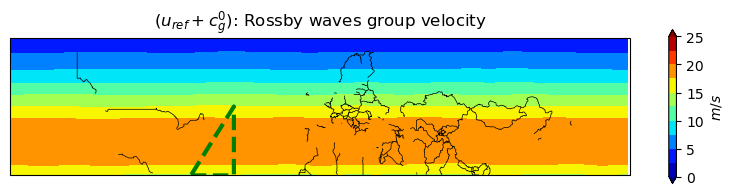

In [18]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,ds_zon_group_velocity,
    levels=np.arange(0, 26, 2.5),
    cmap='jet',#'YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

# Add coastlines and optional borders
ax.set_aspect(1.6)
#ax.coastlines(color='black', linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m/s$',shrink=0.5)
plt.title('$(u_{ref} + c^0_g)$: Rossby waves group velocity')

plt.show()

## Computing $A_0$

The stationary wave component of A0 can be roughly estimated through its mean value. Otherwise a more refined method would be to exclude the grid points during which blocking is happening. In this way, the stationary waves are not influenced by blocking and it is easier to assess causality relationship. In this case we are sticking to the first way because we didn't compute blocking climatology for ERA5

In [19]:
ds = xr.open_dataset('../tot/dw_stat_lwa_2-51.nc').where(ds.lat >= 0, drop=True)
print(ds)
print('data imported')
density_weighted_stat_lwa = ds['dw_stat_lwa']

#the relative error is much smaller than for the other quantities so we do not include it in the analysis for simplicity

<xarray.Dataset> Size: 237kB
Dimensions:          (lat: 61, lon: 240)
Coordinates:
  * lon              (lon) float64 2kB -180.0 -178.5 -177.0 ... 177.0 178.5
  * lat              (lat) float64 488B 0.0 1.5 3.0 4.5 ... 85.5 87.0 88.5 90.0
    time             object 8B ...
Data variables:
    dw_stat_lwa      (lat, lon) float64 117kB 0.004145 0.00797 ... 0.0 0.0
    dw_stat_lwa_std  (lat, lon) float64 117kB 0.0 9.805e-19 ... 0.0 0.0
data imported


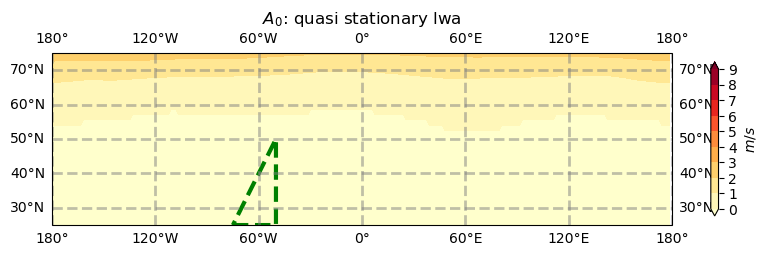

In [20]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,density_weighted_stat_lwa,
    levels=np.arange(0, 10, 1),
    cmap='YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

ax.set_aspect(2)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=2, color='gray', alpha=0.5, linestyle='--')
gl.xlabels_top = False
gl.ylabels_right = False

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m/s$',shrink=0.5)
plt.title('$A_0$: quasi stationary lwa')

plt.show()

### Compute the CARRYING CAPACITY

In [34]:
# use shorter names
A = ds_zon_group_velocity
alpha = alpha
B = np.zeros(density_weighted_stat_lwa.shape)
C = cosphi[0,:,:].copy()


# given stds
sigma_A = ds_zon_group_velocity_std
sigma_alpha = alpha_std

# intermediate
u = A - 2*alpha*B

# partial derivatives
dFC_dA = (u * C) / (2.0 * alpha)
dFC_dalpha = - (C * u * (4.0*B*alpha + u)) / (4.0 * alpha**2)

# variance and std 
FC_std = ((dFC_dA**2) * (sigma_A**2) + (dFC_dalpha**2) * (sigma_alpha**2))**0.5

#computed FC
FC = (u**2 * C) / (4.0 * alpha)


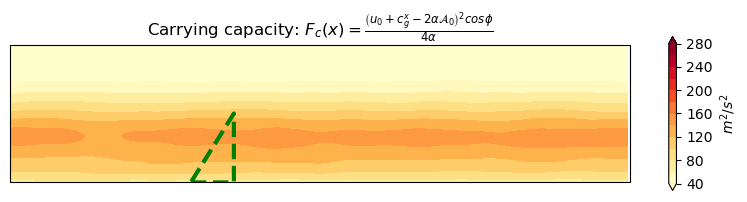

In [35]:
#TOTAL CARRYING CAPACITY

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,FC,
    levels=np.arange(40, 300, 20),
    cmap='YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.set_aspect(1.6)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m^2/s^2$',shrink=0.5)
plt.title('Carrying capacity: ' + r'$F_c(x) = \frac{\left( u_0 + c_g^x - 2\alpha \mathcal{A}_0 \right)^2 cos \phi}{4\alpha}$')

plt.show()

In [36]:
#fluxes approximation 

print(lwa.shape, density_weighted_stat_lwa.shape)

lwa_prime = (lwa-density_weighted_stat_lwa)/cosphi

#COMPUTING F1
u0 = ds_filtered['dw_uref'].mean('time')
F1_approx = lwa_prime*u0*cosphi

#COMPUTING F2
F2_approx = -(lwa_prime**2)*cosphi*alpha
#F2_approx = -lwa**2*alpha

#COMPUTING F3
cg = ds_zon_group_velocity - u0
F3_approx = lwa_prime*cg*cosphi

#COMPUTING STAT_LWA FLUX
FA0 = ds_zon_group_velocity*density_weighted_stat_lwa*cosphi - alpha*(density_weighted_stat_lwa**2)*cosphi

(36000, 61, 240) (61, 240)


In [37]:
#transient flux computation

transient_flux = F1_approx + F2_approx + F3_approx# - FA0
CLIM_transient_flux = transient_flux.mean('time')
PERC_transient_flux = transient_flux.quantile(0.85, dim='time')

In [38]:
transient_flux_real = ds_filtered['F1'] + ds_filtered['F2'] + ds_filtered['F3']# - FA0

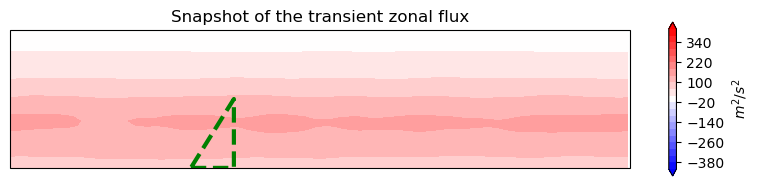

In [39]:
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,PERC_transient_flux,
    levels=np.arange(-420, 430, 40),
    cmap='bwr',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.set_aspect(1.6)
ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m^2/s^2$',shrink=0.5)
plt.title('Snapshot of the transient zonal flux')

plt.show()

In [40]:
# import blocking frequency
ds_blocks = xr.open_dataset("../tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc")
block_freq = ds_blocks['LWAA_freq']

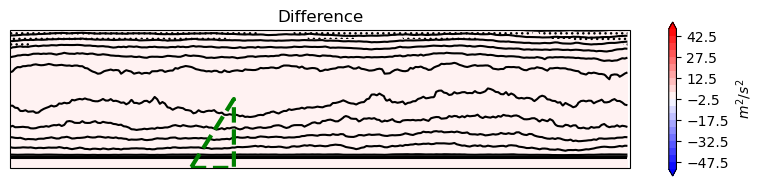

In [44]:
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,PERC_transient_flux-FC,
    levels=np.arange(-420, 420, 40)/8,
    cmap='bwr',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.contour(lon,lat,block_freq,colors='k')

hatch_mask = np.where(r_mask, 1, np.nan)
ax.contourf(
    lon, lat, hatch_mask,
    levels=[0.5, 1.5],
    hatches=['...', None],
    colors='none',
    transform=ccrs.PlateCarree(),
    zorder=10
)

ax.set_aspect(1.6)
ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m^2/s^2$',shrink=0.5)
plt.title('Difference')

plt.show()

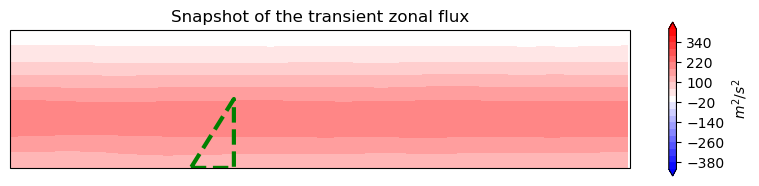

In [42]:
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,transient_flux_real.mean('time'),
    levels=np.arange(-420, 430, 40),
    cmap='bwr',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.set_aspect(1.6)
ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m^2/s^2$',shrink=0.5)
plt.title('Snapshot of the transient zonal flux')

plt.show()

In [43]:
#Create Carrying Capacity Dataset

alpha.name = 'alpha'
ds_out = alpha.to_dataset()
ds_out['zgv'] = ds_zon_group_velocity
ds_out['qslwa'] = density_weighted_stat_lwa
ds_out['FC'] = FC
ds_out['CLIM_transient_flux'] = CLIM_transient_flux
ds_out['PERC_transient_flux'] = PERC_transient_flux
ds_out['ue_A_rvalue'] = ue_A_rvalue

ds_out['alpha_std'] = alpha_std
ds_out['zgv_std'] = ds_zon_group_velocity_std
ds_out['FC_std'] = FC_std

ds_out.to_netcdf('../tot/FC_1.5x1.5_2-51.nc')